# 3. Preprocessing and chronological splits

Closures, the causal anomaly rule, masks and the rolling-origin plan.

In [1]:
import sys
from pathlib import Path
CODE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_DIR))
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, experiment
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TABLES = config.OUTPUT_DIR / "tables"
FIGS = config.FIGURE_DIR

In [2]:
for name in ['m5', 'rossmann']:
    prep = experiment.prepare(name)
    print(name, prep.plan.describe())
    print('  closures:', int(prep.panel.closed.sum()), ' anomalies:', int(prep.anomalies.sum()))

m5 {'n_days': 1941, 'horizon': 28, 'tuning_train_days': 1409, 'validation_days': 140, 'final_train_days': 1549, 'test_days': 392, 'val_origins': [1409, 1437, 1465, 1493, 1521], 'test_origins': [1549, 1577, 1605, 1633, 1661, 1689, 1717, 1745, 1773, 1801, 1829, 1857, 1885, 1913]}
  closures: 50  anomalies: 1
rossmann {'n_days': 942, 'horizon': 28, 'tuning_train_days': 606, 'validation_days': 140, 'final_train_days': 746, 'test_days': 196, 'val_origins': [606, 634, 662, 690, 718], 'test_origins': [746, 774, 802, 830, 858, 886, 914]}
  closures: 3236  anomalies: 0


In [3]:
prep = experiment.prepare('m5')
idx = np.argwhere(prep.anomalies)
[(prep.panel.series_ids[s], str(prep.panel.dates[t].date()), prep.panel.y[s, t]) for s, t in idx]

[('TX_2', '2015-03-24', np.float64(131.0))]

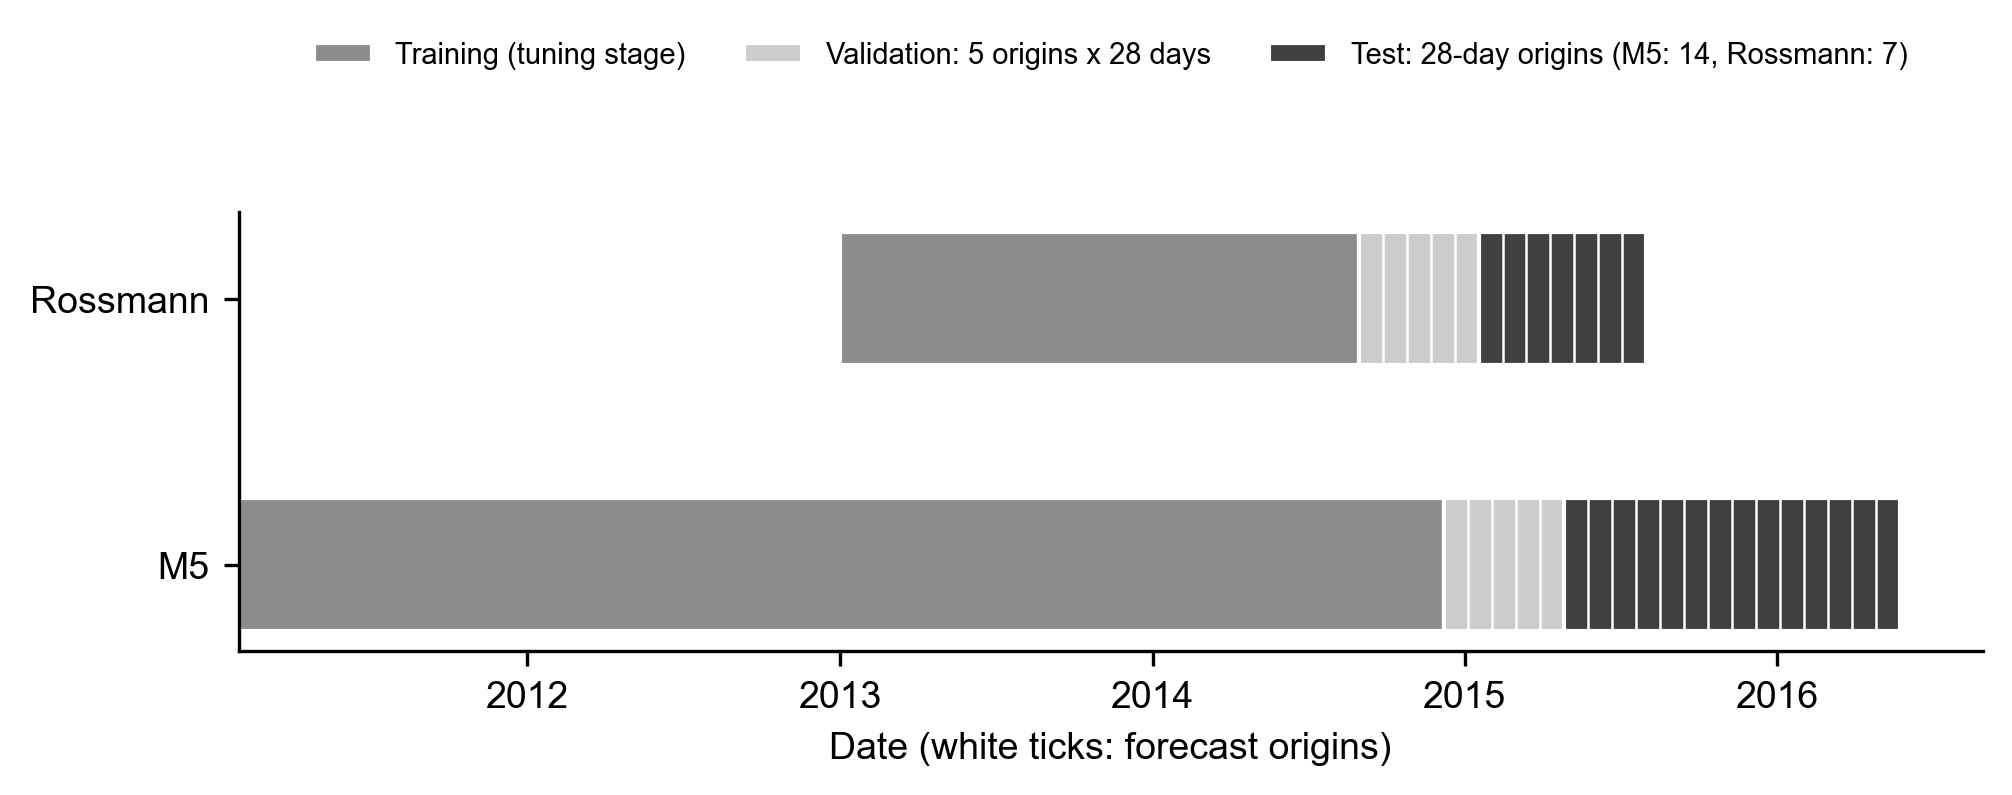

In [4]:
display(Image(filename=str(FIGS / 'eda_split_timeline.png'), width=800))